# Combined BASS / SAFFIRE-V fire-spread model

This notebook creates `combine_fsr_data.csv` from the cleaned BASS and SAFFIRE-V observations and compares pooled raw-scale and positive log-linear models using airflow, thickness, rib width, and initial oxygen. BASS rib width is set to **0 cm as a not-applicable code** (and `rib_width_applicable` remains false); therefore its numeric rib-width terms contribute zero for BASS rows. Do not interpret that zero as a measured physical rib width.

The notebook compares a four-input linear model with the same model plus a quadratic rib-width term, selecting by leave-one-experiment-out RMSE. It reports the held-out SAFFIRE-V experiment separately. Since there is only one Saffire experiment, this is not an independent test of generalization to new Saffire burns.

## Expected-use regions and transfer limits

Use only source-like input combinations, not the rectangular min/max envelope across both datasets. In BASS, thickness is 0.1-0.5 cm, initial oxygen is 17.9-22.2%, and rib width is N/A (coded 0). In SAFFIRE-V, thickness is 1.0 cm, oxygen is 26.9%, rib width is 0.1-1.0 cm, and only 5 and 20 cm/s airflow were observed. Values between the source regimes (for example 0.7 cm thickness or 24% oxygen) are unsupported, even though they fall between global minima and maxima.

BASS and Saffire also differ in geometry, physical scale, pressure reporting, and FSR measurement method. The sample areas are 12-22 cm^2 for BASS (using its prior 10 cm length assumption) versus 800 cm^2 for Saffire. Area is retained as context, not fit as an independent effect: scale is confounded with source/geometry and BASS length is assumed. BASS has no rib-width variation, so a held-out Saffire experiment cannot learn a rib effect from BASS. The BASS-to-Saffire grouped holdout error is reported to expose this transfer problem, not to certify the pooled model. Predictions are exploratory estimates, not measured or validated values.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

input_name = "astroflame_formatted_cgs.csv"
candidate_dirs = [Path.cwd(), Path.cwd() / "elig-data"]
input_path = next(
    (directory / input_name for directory in candidate_dirs if (directory / input_name).is_file()),
    None,
)
if input_path is None:
    raise FileNotFoundError(f"Could not find {input_name} in the current folder or its elig-data subfolder.")

data_dir = input_path.parent
source = pd.read_csv(input_path)
required_columns = {
    "dataset",
    "experiment_id",
    "observation_id",
    "airflow_cm_s",
    "thickness_cm",
    "rib_width_cm",
    "oxygen_initial_pct",
    "fsr_cm_s",
    "sample_width_cm",
    "sample_length_cm",
}
missing_columns = required_columns.difference(source.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

dataset_names = source["dataset"].astype("string").str.strip().str.upper()
selected = dataset_names.str.startswith("BASS", na=False) | dataset_names.isin({"SAFFIRE-V", "SAFFIRE-5"})
combined = source.loc[selected].copy()
if combined.empty:
    raise ValueError("No BASS or SAFFIRE-V observations were found.")

combined_names = combined["dataset"].astype("string").str.strip().str.upper()
is_bass = combined_names.str.startswith("BASS", na=False)
is_saffire = combined_names.isin({"SAFFIRE-V", "SAFFIRE-5"})
numeric_columns = [
    "airflow_cm_s",
    "thickness_cm",
    "fsr_cm_s",
    "oxygen_initial_pct",
    "sample_width_cm",
]
for column in numeric_columns:
    combined[column] = pd.to_numeric(combined[column], errors="raise")
original_rib_width = pd.to_numeric(combined["rib_width_cm"], errors="raise")
if original_rib_width.loc[is_bass].notna().any():
    raise ValueError("BASS rib widths are expected to be unavailable before applying the 0 cm code.")
if original_rib_width.loc[is_saffire].isna().any():
    raise ValueError("SAFFIRE-V rib widths must be present in the formatted data.")

combined["rib_width_applicable"] = original_rib_width.notna()
combined["rib_width_cm"] = original_rib_width.fillna(0.0)
combined["oxygen_percent"] = pd.to_numeric(combined["oxygen_initial_pct"], errors="raise")
combined["sample_length_cm"] = pd.to_numeric(combined["sample_length_cm"], errors="coerce")
combined["sample_length_for_area_cm"] = combined["sample_length_cm"]
bass_missing_length = is_bass & combined["sample_length_for_area_cm"].isna()
combined.loc[bass_missing_length, "sample_length_for_area_cm"] = 10.0
combined["planform_area_cm2"] = combined["sample_width_cm"] * combined["sample_length_for_area_cm"]
combined["planform_area_basis"] = np.where(
    bass_missing_length,
    "BASS comparison assumption: 10 cm length",
    "reported sample dimensions",
)
combined["sample_volume_cm3"] = combined["planform_area_cm2"] * pd.to_numeric(
    combined["thickness_cm"], errors="raise"
)

model_columns = [
    "dataset",
    "experiment_id",
    "observation_id",
    "airflow_cm_s",
    "thickness_cm",
    "rib_width_cm",
    "rib_width_applicable",
    "oxygen_percent",
    "fsr_cm_s",
    "sample_width_cm",
    "sample_length_cm",
    "planform_area_cm2",
    "planform_area_basis",
    "sample_volume_cm3",
    "material",
    "geometry",
    "flow_direction",
    "measurement_method",
    "data_quality",
    "notes",
    "source_location",
    "pressure_kpa",
]
combined = combined[model_columns]
combined_path = data_dir / "combine_fsr_data.csv"
combined.to_csv(combined_path, index=False)

if combined.loc[is_bass, "rib_width_cm"].ne(0).any():
    raise AssertionError("BASS N/A rib widths must be represented by 0 cm.")
if combined.loc[is_bass, "rib_width_applicable"].any():
    raise AssertionError("BASS rib-width applicability flags must remain false.")
if combined.loc[is_saffire, "rib_width_cm"].le(0).any():
    raise AssertionError("SAFFIRE-V rib widths must remain positive measurements.")
if combined[["airflow_cm_s", "thickness_cm", "oxygen_percent", "fsr_cm_s"]].isna().any().any():
    raise ValueError("Combined model inputs or FSR contain missing values.")

print(f"Wrote {combined_path.name}: {len(combined)} observations.")
print("Rows by dataset:")
print(combined.groupby("dataset").size().to_string())
print("BASS rows use rib_width_cm=0 with rib_width_applicable=False; this is an N/A code.")
print("Saffire footprint:", combined.loc[is_saffire, "planform_area_cm2"].unique().tolist(), "cm^2")
print("BASS comparison footprints:", sorted(combined.loc[is_bass, "planform_area_cm2"].unique().tolist()), "cm^2")


Wrote combine_fsr_data.csv: 57 observations.
Rows by dataset:
dataset
BASS-II PSI-25    39
SAFFIRE-V         18
BASS rows use rib_width_cm=0 with rib_width_applicable=False; this is an N/A code.
Saffire footprint: [800.0] cm^2
BASS comparison footprints: [12.0, 22.0] cm^2


In [2]:
model_data = combined.copy()
model_data["rib_width_squared"] = model_data["rib_width_cm"] ** 2
model_data["validation_group"] = (
    model_data["dataset"].astype(str) + " | " + model_data["experiment_id"].astype(str)
)
target = model_data["fsr_cm_s"].to_numpy(dtype=float)
model_specs = [
    ("Raw-scale four-input linear", ["airflow_cm_s", "thickness_cm", "rib_width_cm", "oxygen_percent"], "raw"),
    ("Log-linear four-input", ["airflow_cm_s", "thickness_cm", "rib_width_cm", "oxygen_percent"], "log"),
    (
        "Raw-scale linear plus quadratic rib width",
        ["airflow_cm_s", "thickness_cm", "rib_width_cm", "oxygen_percent", "rib_width_squared"],
        "raw",
    ),
    (
        "Log-linear plus quadratic rib width",
        ["airflow_cm_s", "thickness_cm", "rib_width_cm", "oxygen_percent", "rib_width_squared"],
        "log",
    ),
]
group_ids = model_data["validation_group"].unique()
model_results = []
cv_predictions = {}
fitted_predictions = {}

def design_matrix(data, features):
    return np.column_stack(
        [np.ones(len(data))]
        + [data[feature].to_numpy(dtype=float) for feature in features]
    )

for model_name, features, target_scale in model_specs:
    full_design = design_matrix(model_data, features)
    full_rank = int(np.linalg.matrix_rank(full_design))
    if full_rank != full_design.shape[1]:
        raise ValueError(f"Full combined model is rank-deficient: {model_name}, rank {full_rank}/{full_design.shape[1]}.")
    fit_target = np.log(target) if target_scale == "log" else target
    full_coefficients = np.linalg.lstsq(full_design, fit_target, rcond=None)[0]
    full_residuals = fit_target - full_design @ full_coefficients
    smearing_factor = float(np.mean(np.exp(full_residuals))) if target_scale == "log" else 1.0
    linear_predictions = full_design @ full_coefficients
    fitted = np.exp(linear_predictions) * smearing_factor if target_scale == "log" else linear_predictions
    cv_predicted = np.full(len(model_data), np.nan, dtype=float)
    group_mean_squared_errors = []
    fold_ranks = []
    for held_out_group in group_ids:
        held_out = model_data["validation_group"].eq(held_out_group).to_numpy()
        training = model_data.loc[~held_out]
        validation = model_data.loc[held_out]
        training_design = design_matrix(training, features)
        fold_ranks.append(int(np.linalg.matrix_rank(training_design)))
        fold_coefficients = np.linalg.lstsq(
            training_design,
            fit_target[~held_out],
            rcond=None,
        )[0]
        validation_design = design_matrix(validation, features)
        fold_linear_predictions = validation_design @ fold_coefficients
        if target_scale == "log":
            fold_residuals = fit_target[~held_out] - training_design @ fold_coefficients
            fold_smearing = float(np.mean(np.exp(fold_residuals)))
            fold_predictions = np.exp(fold_linear_predictions) * fold_smearing
        else:
            fold_predictions = fold_linear_predictions
        residuals = target[held_out] - fold_predictions
        cv_predicted[held_out] = fold_predictions
        group_mean_squared_errors.append(float(np.mean(residuals**2)))
    row_weighted_rmse = float(np.sqrt(np.mean((target - cv_predicted) ** 2)))
    equal_experiment_rmse = float(np.sqrt(np.mean(group_mean_squared_errors)))
    saffire_rows = model_data["dataset"].eq("SAFFIRE-V").to_numpy()
    saffire_holdout_rmse = float(
        np.sqrt(np.mean((target[saffire_rows] - cv_predicted[saffire_rows]) ** 2))
    )
    linear_equation = f"{full_coefficients[0]:.7g}"
    for coefficient, feature in zip(full_coefficients[1:], features):
        linear_equation += f" + ({coefficient:.7g} * {feature})"
    equation = (
        f"FSR = {smearing_factor:.7g} * exp({linear_equation})"
        if target_scale == "log"
        else f"FSR = {linear_equation}"
    )
    model_results.append(
        {
            "model": model_name,
            "features": features,
            "target_scale": target_scale,
            "coefficients": full_coefficients,
            "smearing_factor": smearing_factor,
            "equation": equation,
            "full_rank": full_rank,
            "min_fold_rank": min(fold_ranks),
            "training_rmse_cm_s": float(np.sqrt(np.mean((target - fitted) ** 2))),
            "training_r2": float(1 - np.sum((target - fitted) ** 2) / np.sum((target - target.mean()) ** 2)),
            "row_weighted_cv_rmse_cm_s": row_weighted_rmse,
            "equal_experiment_cv_rmse_cm_s": equal_experiment_rmse,
            "saffire_holdout_rmse_cm_s": saffire_holdout_rmse,
        }
    )
    cv_predictions[model_name] = cv_predicted
    fitted_predictions[model_name] = fitted

model_summary = pd.DataFrame(
    [
        {key: value for key, value in result.items() if key not in {"features", "coefficients", "equation"}}
        for result in model_results
    ]
).sort_values("equal_experiment_cv_rmse_cm_s")
best_model_name = model_summary.iloc[0]["model"]
best_model = next(result for result in model_results if result["model"] == best_model_name)
best_cv_predictions = cv_predictions[best_model_name]
best_fitted_predictions = fitted_predictions[best_model_name]
print("Grouped leave-one-experiment-out model comparison (lower RMSE is better):")
print(
    model_summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.6g}",
    )
)
print(f"\nSelected pooled model: {best_model_name}")
print(best_model["equation"])
print(
    "Fold ranks can be deficient when the held-out group contains the only positive rib widths; "
    "the minimum fold rank is shown so that the missing-transfer signal is visible."
)

prediction_rows = model_data[
    ["dataset", "experiment_id", "observation_id", "airflow_cm_s", "thickness_cm", "rib_width_cm", "rib_width_applicable", "oxygen_percent", "fsr_cm_s"]
].copy()
prediction_rows["fitted_fsr_cm_s"] = best_fitted_predictions
prediction_rows["leave_one_experiment_out_fsr_cm_s"] = best_cv_predictions
prediction_path = data_dir / "combine_fsr_model_predictions.csv"
prediction_rows.to_csv(prediction_path, index=False)
print(f"Saved row-level predictions: {prediction_path.name}")


Grouped leave-one-experiment-out model comparison (lower RMSE is better):
                                    model target_scale  smearing_factor  full_rank  min_fold_rank  training_rmse_cm_s  training_r2  row_weighted_cv_rmse_cm_s  equal_experiment_cv_rmse_cm_s  saffire_holdout_rmse_cm_s
      Log-linear plus quadratic rib width          log          1.20813          6              4           0.0112742     0.326245                  0.0167773                     0.00829326                  0.0287406
                    Log-linear four-input          log          1.21047          5              4           0.0106316     0.400861                  0.0169067                      0.0086284                  0.0287406
              Raw-scale four-input linear          raw                1          5              4           0.0101954     0.449019                  0.0200105                      0.0112793                  0.0329096
Raw-scale linear plus quadratic rib width          raw        

## Conservative prediction-range checks

The bounds below are empirical data ranges, not guarantees. They are split by source regime so that the model does not silently treat unsupported combinations inside the global min/max box as validated. BASS airflow is observed at a set of discrete levels; Saffire has only 5 and 20 cm/s. Between-setting airflow values are interpolations, not measured conditions.

The prediction helper rejects inputs outside the BASS-like or Saffire-like envelope. It cannot certify unobserved combinations within either envelope, especially because Saffire contributes only one experiment.

BASS-like input envelope (rib width is N/A-coded zero): {'airflow_cm_s': (2.0, 21.0), 'thickness_cm': (0.1, 0.5), 'rib_width_cm': (0.0, 0.0), 'oxygen_percent': (17.9, 22.2)}
SAFFIRE-V input envelope: {'airflow_cm_s': (5.0, 20.0), 'thickness_cm': (1.0, 1.0), 'rib_width_cm': (0.1, 1.0), 'oxygen_percent': (26.9, 26.9)}
SAFFIRE-V observed airflow levels: [5, 20]
Combined observed FSR range (cm/s): (0.0012000000000000001, 0.088)

Example BASS-like prediction: {'fsr_cm_s': 0.013769105204452481, 'input_regime': 'BASS-like (rib width N/A)'}
Example Saffire-like prediction: {'fsr_cm_s': 0.015990753669660657, 'input_regime': 'SAFFIRE-V-like (ribbed)'}


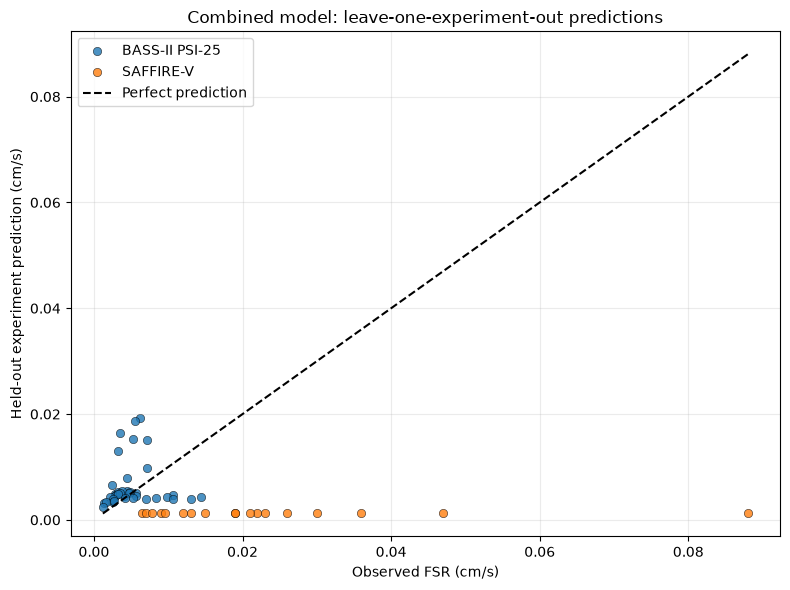

Saved combined model outputs:
combine_fsr_model_predictions.csv
combine_fsr_grouped_predictions.png
combine_fsr_model_results.txt


In [3]:
bass_rows = model_data[model_data["dataset"].astype("string").str.upper().str.startswith("BASS", na=False)]
saffire_rows = model_data[model_data["dataset"].astype("string").str.upper().eq("SAFFIRE-V")]
input_features = ["airflow_cm_s", "thickness_cm", "rib_width_cm", "oxygen_percent"]
bass_bounds = {
    feature: (float(bass_rows[feature].min()), float(bass_rows[feature].max()))
    for feature in input_features
}
saffire_bounds = {
    feature: (float(saffire_rows[feature].min()), float(saffire_rows[feature].max()))
    for feature in input_features
}
print("BASS-like input envelope (rib width is N/A-coded zero):", bass_bounds)
print("SAFFIRE-V input envelope:", saffire_bounds)
print("SAFFIRE-V observed airflow levels:", sorted(saffire_rows["airflow_cm_s"].unique().tolist()))
print("Combined observed FSR range (cm/s):", (float(target.min()), float(target.max())))

def predict_combine_fsr(airflow_cm_s, thickness_cm, rib_width_cm, oxygen_percent):
    values = {
        "airflow_cm_s": float(airflow_cm_s),
        "thickness_cm": float(thickness_cm),
        "rib_width_cm": float(rib_width_cm),
        "oxygen_percent": float(oxygen_percent),
    }
    if not np.isfinite(list(values.values())).all():
        raise ValueError("All prediction inputs must be finite numbers.")
    if values["thickness_cm"] <= 0 or values["rib_width_cm"] < 0:
        raise ValueError("Thickness must be positive and rib width cannot be negative.")

    if values["rib_width_cm"] == 0:
        regime = "BASS-like (rib width N/A)"
        bounds = bass_bounds
        if not all(bounds[name][0] <= values[name] <= bounds[name][1] for name in values):
            raise ValueError(f"Input is outside the observed {regime} envelope: {bounds}")
    else:
        regime = "SAFFIRE-V-like (ribbed)"
        bounds = saffire_bounds
        if not all(bounds[name][0] <= values[name] <= bounds[name][1] for name in values):
            raise ValueError(f"Input is outside the observed {regime} envelope: {bounds}")
        if not np.isclose(values["thickness_cm"], saffire_rows["thickness_cm"].iloc[0]):
            raise ValueError("SAFFIRE-V ribbed support only covers its observed 1.0 cm thickness.")
        if not np.isclose(values["oxygen_percent"], saffire_rows["oxygen_percent"].iloc[0]):
            raise ValueError("SAFFIRE-V ribbed support only covers its observed 26.9% oxygen.")

    row = pd.DataFrame([values])
    if "rib_width_squared" in best_model["features"]:
        row["rib_width_squared"] = row["rib_width_cm"] ** 2
    design = design_matrix(row, best_model["features"])
    linear_estimate = float((design @ best_model["coefficients"])[0])
    estimate = (
        float(np.exp(linear_estimate) * best_model["smearing_factor"])
        if best_model["target_scale"] == "log"
        else linear_estimate
    )
    if not np.isfinite(estimate) or estimate <= 0:
        raise ValueError("This input yields a non-positive or non-finite FSR estimate; do not use it.")
    return {"fsr_cm_s": estimate, "input_regime": regime}

example_bass = bass_rows.iloc[0]
example_saffire = saffire_rows.iloc[0]
print("\nExample BASS-like prediction:", predict_combine_fsr(
    example_bass["airflow_cm_s"], example_bass["thickness_cm"], 0, example_bass["oxygen_percent"]
))
print("Example Saffire-like prediction:", predict_combine_fsr(
    example_saffire["airflow_cm_s"], example_saffire["thickness_cm"], example_saffire["rib_width_cm"], example_saffire["oxygen_percent"]
))

import matplotlib.pyplot as plt

fig, axis = plt.subplots(figsize=(8, 6))
for dataset_name, group in prediction_rows.groupby("dataset"):
    axis.scatter(
        group["fsr_cm_s"],
        group["leave_one_experiment_out_fsr_cm_s"],
        label=dataset_name,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.4,
    )
limits = [float(target.min()), float(target.max())]
axis.plot(limits, limits, color="black", linestyle="--", label="Perfect prediction")
axis.set(
    title="Combined model: leave-one-experiment-out predictions",
    xlabel="Observed FSR (cm/s)",
    ylabel="Held-out experiment prediction (cm/s)",
)
axis.legend()
axis.grid(alpha=0.25)
fig.tight_layout()
chart_path = data_dir / "combine_fsr_grouped_predictions.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()

report_lines = [
    "Combined BASS / SAFFIRE-V exploratory model",
    f"Rows: {len(model_data)}; experiment groups: {len(group_ids)}",
    f"Selected model: {best_model_name}",
    best_model["equation"],
    f"Equal-experiment grouped CV RMSE: {best_model['equal_experiment_cv_rmse_cm_s']:.7g} cm/s",
    f"Held-out Saffire experiment RMSE: {best_model['saffire_holdout_rmse_cm_s']:.7g} cm/s",
    f"BASS-like envelope: {bass_bounds}",
    f"SAFFIRE-V-like envelope: {saffire_bounds}",
    "BASS rib_width_cm=0 denotes N/A, not a physical 0 cm rib measurement.",
    "Only source-like input combinations are supported; global min/max combinations are not.",
    "Saffire holdout has no positive rib widths in training, so BASS-only training cannot learn a rib effect.",
    "The Saffire data are one approximate digitized experiment; the combined model is exploratory and unvalidated for new Saffire burns.",
]
report_path = data_dir / "combine_fsr_model_results.txt"
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")
print("Saved combined model outputs:")
print(prediction_path.name)
print(chart_path.name)
print(report_path.name)
